# 8. Immune Infiltration

> Gene set:
> 
> [TISIDB](http://cis.hku.hk/TISIDB): 988 genes related to anti-tumor immunity.
> - Beibei Ru, Ching Ngar Wong, Yin Tong, Jia Yi Zhong, Sophia Shek Wa Zhong, Wai Chung Wu, Ka Chi Chu, Choi Yiu Wong, Chit Ying Lau, Ian Chen, Nam Wai Chan, Jiangwen Zhang, TISIDB: an integrated repository portal for tumor–immune system interactions, Bioinformatics, Volume 35, Issue 20, October 2019, Pages 4200–4202, https://doi.org/10.1093/bioinformatics/btz210.

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(ggpubr))
suppressPackageStartupMessages(library(SummarizedExperiment))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/database/UCSC_Xena/TCGA-COAD"

In [3]:
eSet <- readRDS(file.path(data_dir, "TCGA-COAD.star_counts.rds"))
eSet

class: SummarizedExperiment 
dim: 21284 514 
metadata(0):
assays(2): counts TPM
rownames(21284): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): basepairs gene_name gene_type
colnames(514): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(13): Patient_ID Gender ... Vital_Status Group

In [4]:
sample_cols <- colnames(eSet)

gene_anno <- rowData(eSet) |>
    as.data.frame() |>
    rownames_to_column("gene_id")

expr_df <- assay(eSet, "counts") |>
    as.data.frame() |>
    rownames_to_column(var = "gene_id") |> 
    left_join(gene_anno, by = "gene_id") |>
    mutate(
        symbol = coalesce(na_if(gene_name, ""), gene_id), 
        sum_expr = rowSums(
            across(all_of(sample_cols)), na.rm = TRUE)) |>
    arrange(symbol, desc(sum_expr)) |>
    distinct(symbol, .keep_all = TRUE)
    
gene_length <- expr_df$basepairs

expr_mat <- expr_df |>
    column_to_rownames("symbol") |>
    select(all_of(sample_cols)) |>
    as.matrix()

storage.mode(expr_mat) <- "integer"

dim(expr_mat)

[1] 21270   514

In [5]:
calculate_tpm <- function(counts, basepairs) {
    rpk <- sweep(counts, 1, basepairs / 1000, FUN = "/")
    tpm <- sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6
    return(tpm)
}

In [6]:
norm_mat <- calculate_tpm(expr_mat, gene_length)
norm_mat[1:6, 1:6]

,TCGA-5M-AAT6-01A,TCGA-AA-3552-01A,TCGA-AA-3867-01A,TCGA-AD-6895-01A,TCGA-AA-3560-01A,TCGA-CM-6676-01A
A1BG-AS1,0.5034967,0.3448274,0.5077013,0.1621759,0.1016892,0.1817668
A1CF,0.1664968,3.5134835,7.5276403,0.3513783,4.1623534,6.2426586
A2M,160.2696288,155.7432489,183.3635897,143.4785310,150.1263510,180.0870851
A2M-AS1,0.7457410,0.6413170,0.5810665,0.3402870,0.4655351,0.3120495
A4GALT,8.4811936,5.8466882,15.3036104,38.4830351,1.5326060,11.0721207
AAAS,32.4712063,29.4430769,28.8094431,39.6273468,52.8403558,40.7221663


## Tumor Purity

### [ESTIMATE](https://bioinformatics.mdanderson.org/estimate/index.html)

> ESTIMATE provides researchers with scores for tumor purity, the level of stromal cells present, and the infiltration level of immune cells in tumor tissues based on expression data.
> - Yoshihara, K., Shahmoradgoli, M., Martínez, E. et al. Inferring tumour purity and stromal and immune cell admixture from expression data. Nat Commun 4, 2612 (2013). https://doi.org/10.1038/ncomms3612

In [7]:
# install.packages("estimate", repos = "http://r-forge.r-project.org", dependencies = TRUE)
suppressPackageStartupMessages(library(estimate))
# install.packages("tidyestimate")
# suppressPackageStartupMessages(library(tidyestimate))

In [8]:
# write.table(
#     norm_mat, file = file.path(data_dir, "estimate_expr_matrix.txt"),
#     sep = "\t", quote = FALSE, row.names = TRUE, col.names = TRUE)
# filterCommonGenes(
#     input.f = file.path(data_dir, "estimate_expr_matrix.txt"), 
#     output.f = file.path(data_dir, "estimate_genes.gct"), 
#     id = "GeneSymbol")

In [9]:
data(common_genes)
common_genes <- intersect(rownames(norm_mat), common_genes$GeneSymbol)

sub_mat <- norm_mat[common_genes, ]
dim(sub_mat)

[1] 9015  514

In [10]:
as.data.frame(sub_mat) |> 
    outputGCT(file.path(data_dir, "estimate_common_genes.gct"))

In [11]:
estimateScore(
    input.ds = file.path(data_dir, "estimate_common_genes.gct"), 
    output.ds = file.path(data_dir, "estimate_score.txt"), 
    platform = "illumina")

# immunedeconv::deconvolute_estimate(norm_mat)

[1] "1 gene set: StromalSignature  overlap= 136"
[1] "2 gene set: ImmuneSignature  overlap= 137"


In [12]:
estimate_result <- file.path(data_dir, "estimate_score.txt") |>
    read.table(
        header = TRUE, skip = 2, sep = "\t", quote = "", 
        check.names = FALSE) |>
    column_to_rownames("NAME") |>
    select(-Description) |>
    t() |> as.data.frame() |>
    mutate(
        TumorPurity = cos(0.6049872018 + 0.0001467884 * ESTIMATEScore))
    
rownames(estimate_result) <- gsub("\\.", "-", rownames(estimate_result))

head(estimate_result)

,StromalScore,ImmuneScore,ESTIMATEScore,TumorPurity
,<dbl>,<dbl>,<dbl>,<dbl>
TCGA-5M-AAT6-01A,113.4626,1190.4532,1303.91577,0.6992940
TCGA-AA-3552-01A,-792.2974,856.8264,64.52901,0.8170853
TCGA-AA-3867-01A,-67.3471,172.7941,105.44696,0.8136078
TCGA-AD-6895-01A,-577.1457,544.0146,-33.13112,0.8252656
TCGA-AA-3560-01A,-674.0451,443.4855,-230.55964,0.8412832
TCGA-CM-6676-01A,-656.0247,-546.7470,-1202.77174,0.9096173


In [13]:
estimate_result <- estimate_result |> 
    merge(colData(eSet) |> as.data.frame(), by = "row.names")

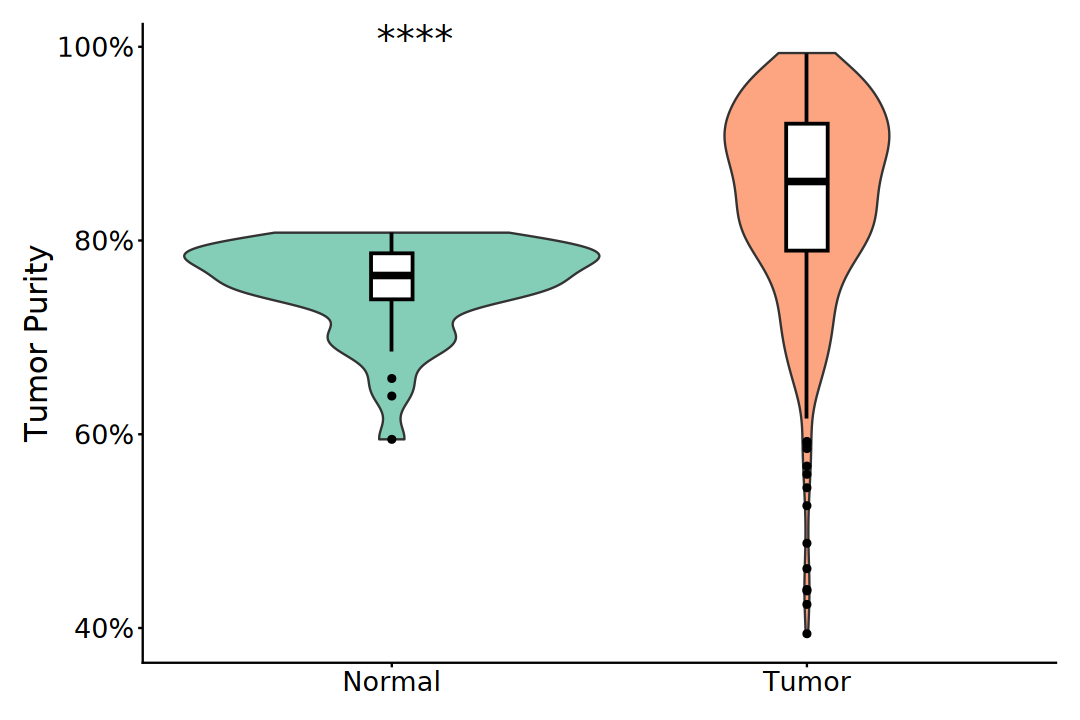

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(estimate_result, aes(x = Group, y = TumorPurity)) +
    geom_violin(
        aes(fill = Group), width = 1, alpha = 0.8,
        trim = TRUE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    stat_compare_means(
        method = "wilcox.test", label = "p.signif", size = 8) +
    scale_y_continuous(labels = scales::label_percent()) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Tumor Purity") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

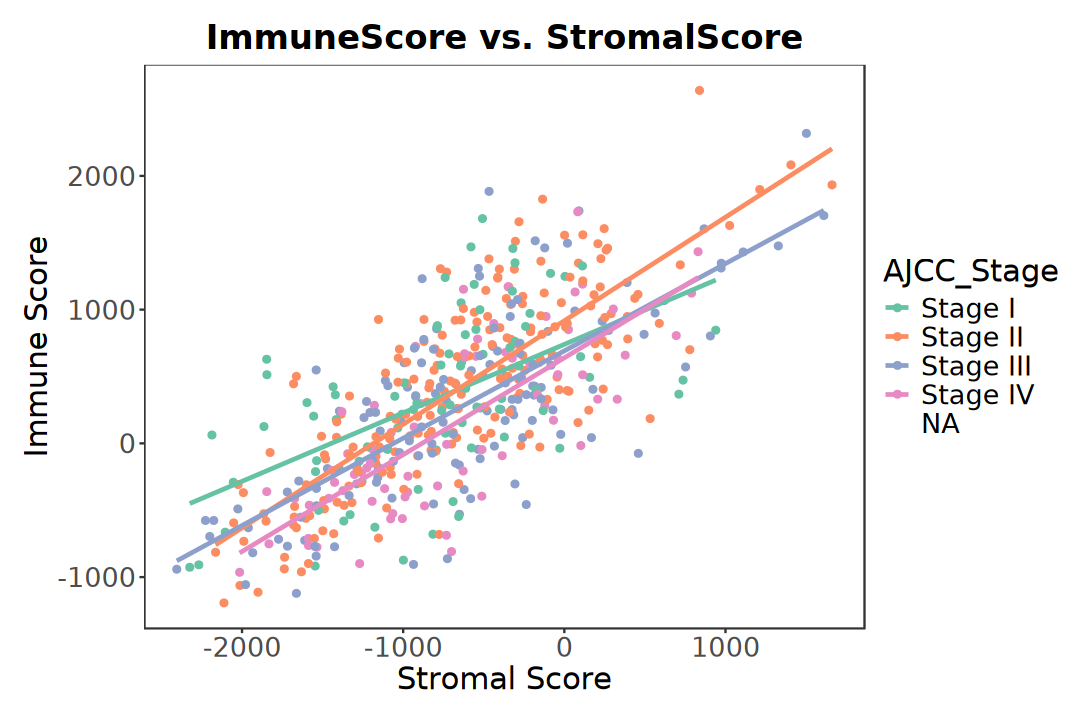

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(estimate_result, aes(x = StromalScore, y = ImmuneScore)) +
    geom_point(aes(color = AJCC_Stage), na.rm = TRUE) +
    geom_smooth(
        aes(color = AJCC_Stage),
        formula = 'y ~ x', method = "lm", se = FALSE) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "ImmuneScore vs. StromalScore", 
        x = "Stromal Score", y = "Immune Score") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

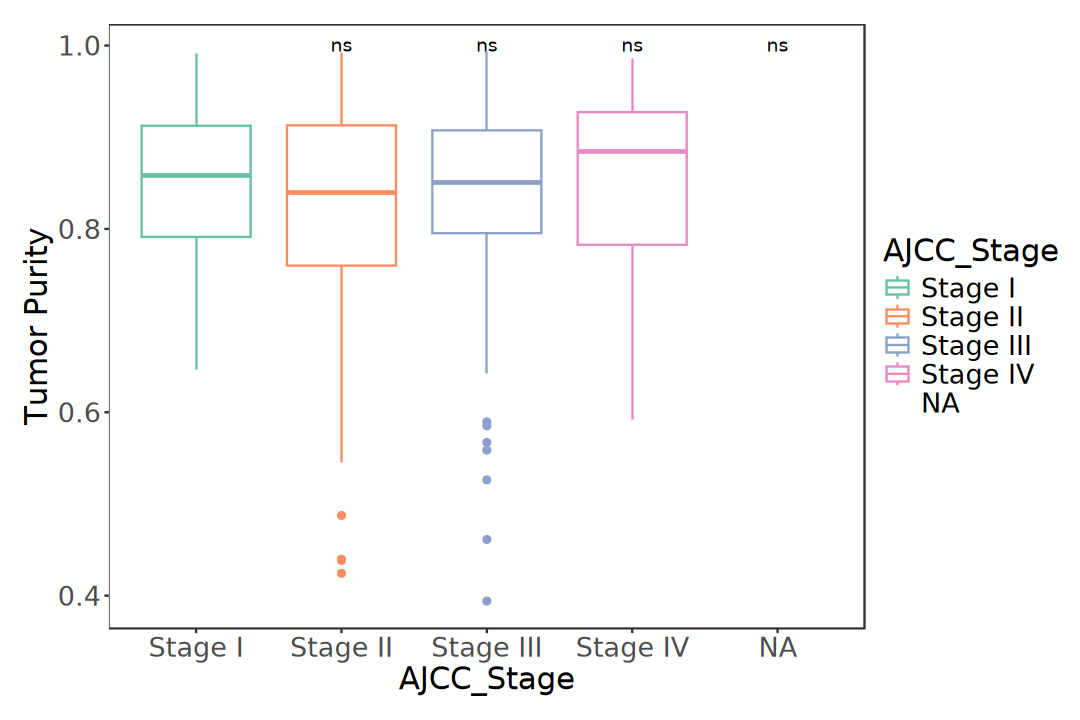

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(estimate_result, aes(x = AJCC_Stage, y = TumorPurity)) +
    geom_boxplot(aes(color = AJCC_Stage)) +
    stat_compare_means(
        method = "wilcox.test", label = "p.signif", 
        hide.ns = FALSE, ref.group = "Stage I") +
    scale_color_brewer(palette = "Set2") + 
    labs(x = "AJCC_Stage", y = "Tumor Purity") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [17]:
plot_df <- estimate_result |> 
    pivot_longer(
        cols = c("StromalScore", "ImmuneScore", "ESTIMATEScore"), 
        names_to = "Class", values_to = "Score")

In [18]:
# suppressPackageStartupMessages(library(rstatix))

# stat_test <- result_estimate_long |>
#     group_by(Class) |>
#     pairwise_t_test(
#         formula = score ~ Stage, p.adjust.method = "BH", 
#         pool.sd = FALSE) |> 
#     add_significance("p.adj") |>
#     add_xy_position(x  = "Group1", dodge = 0.8)

# comparisons <- list(
#     c("Stage I", "Stage II"), c("Stage I", "Stage III"), 
#     c("Stage I", "Stage IV"), c("Stage II", "Stage III"), 
#     c("Stage II", "Stage IV"), c("Stage III", "Stage IV"))

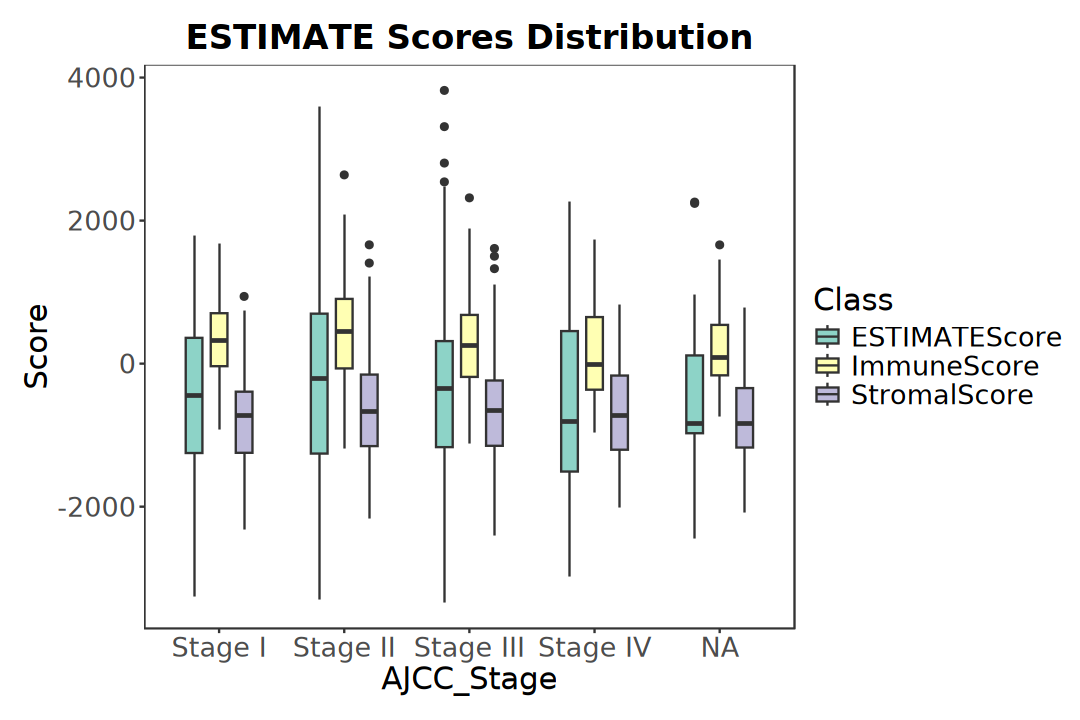

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(plot_df, aes(x = AJCC_Stage, y = Score)) +
    geom_boxplot(
        aes(fill = Class), width = 0.4,
        position = position_dodge(0.6)) +
    scale_fill_brewer(palette = "Set3") + 
    labs(
        title = "ESTIMATE Scores Distribution", 
        x = "AJCC_Stage", y = "Score") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## Gene Marker

> quantify the signature enrichment score of a list of cell-specific marker genes from gene expression profiles

### ssGASE



In [20]:
# suppressPackageStartupMessages(library(GSVA))

In [21]:
# ssgsea.score <- gsva(norm_mat, geneSets, method = "ssgsea")

### [xCell](https://github.com/dviraran/xCell)

> xCell (cell types enrichment analysis) is a R package that performs cell type enrichment analysis from gene expression data for 64 immune and stroma cell types.
> 
> Input: gene expression matrix, normalizing to gene length, rownames is gene symbol
> 
> - Aran, D., Hu, Z. & Butte, A.J. xCell: digitally portraying the tissue cellular heterogeneity landscape. Genome Biol 18, 220 (2017). https://doi.org/10.1186/s13059-017-1349-1.
> - Aran, D. (2020). Cell-Type Enrichment Analysis of Bulk Transcriptomes Using xCell. In: Boegel, S. (eds) Bioinformatics for Cancer Immunotherapy. Methods in Molecular Biology, vol 2120. Humana, New York, NY. https://doi.org/10.1007/978-1-0716-0327-7_19.

In [22]:
# remotes::install_github('dviraran/xCell')
suppressPackageStartupMessages(library(xCell))

In [23]:
xcell_result <- xCellAnalysis(norm_mat)

[1] "Num. of genes: 9674"


ℹ GSVA version 2.4.9

ℹ Searching for rows with constant values

ℹ Calculating ssGSEA scores for 488 gene sets

ℹ Calculating ranks

ℹ Calculating rank weights

Calculating ssGSEA scores ■■■■■■■■                          25% | ETA:  3s

Calculating ssGSEA scores ■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■  100% | ETA:  0s

✔ Calculations finished



In [24]:
dim(xcell_result)
xcell_result[1:6, 1:6]

[1]  67 514

,TCGA-5M-AAT6-01A,TCGA-AA-3552-01A,TCGA-AA-3867-01A,TCGA-AD-6895-01A,TCGA-AA-3560-01A,TCGA-CM-6676-01A
aDC,0.46045411,0.324435575,0.145407968,0.22591617,1.462983e-01,3.465304e-02
Adipocytes,0.00000000,0.000000000,0.000000000,0.00000000,5.695162e-19,2.864761e-03
Astrocytes,0.11954353,0.000000000,0.109139129,0.05365359,3.038609e-02,6.153805e-02
B-cells,0.03179255,0.052156088,0.000000000,0.00000000,3.425329e-03,4.765855e-19
Basophils,0.05239090,0.063923899,0.001444181,0.06423549,6.334325e-02,6.524169e-03
CD4+ memory T-cells,0.02732744,0.008968592,0.000000000,0.01764933,1.063136e-02,1.437508e-03


In [25]:
top_idx <- xcell_result |> rowSds() |> 
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 20) |>
    pull(row)

In [26]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(
        Gender, Tissue_Type, AJCC_Stage, AJCC_T, AJCC_N, AJCC_M)

In [27]:
make_colors <- function(x, palette) {
    setNames(scales::brewer_pal(
        palette = palette)(nlevels(x)), levels(x))
}

palette_map <- c(
    Gender = "Dark2", AJCC_Stage = "Set2", AJCC_T = "Reds",
    AJCC_N = "Blues", AJCC_M = "Greens", Tissue_Type = "Set1")

anno_colors <- lapply(
    names(palette_map), 
    function(var) make_colors(eSet[[var]], palette_map[[var]])
)

names(anno_colors) <- names(palette_map)

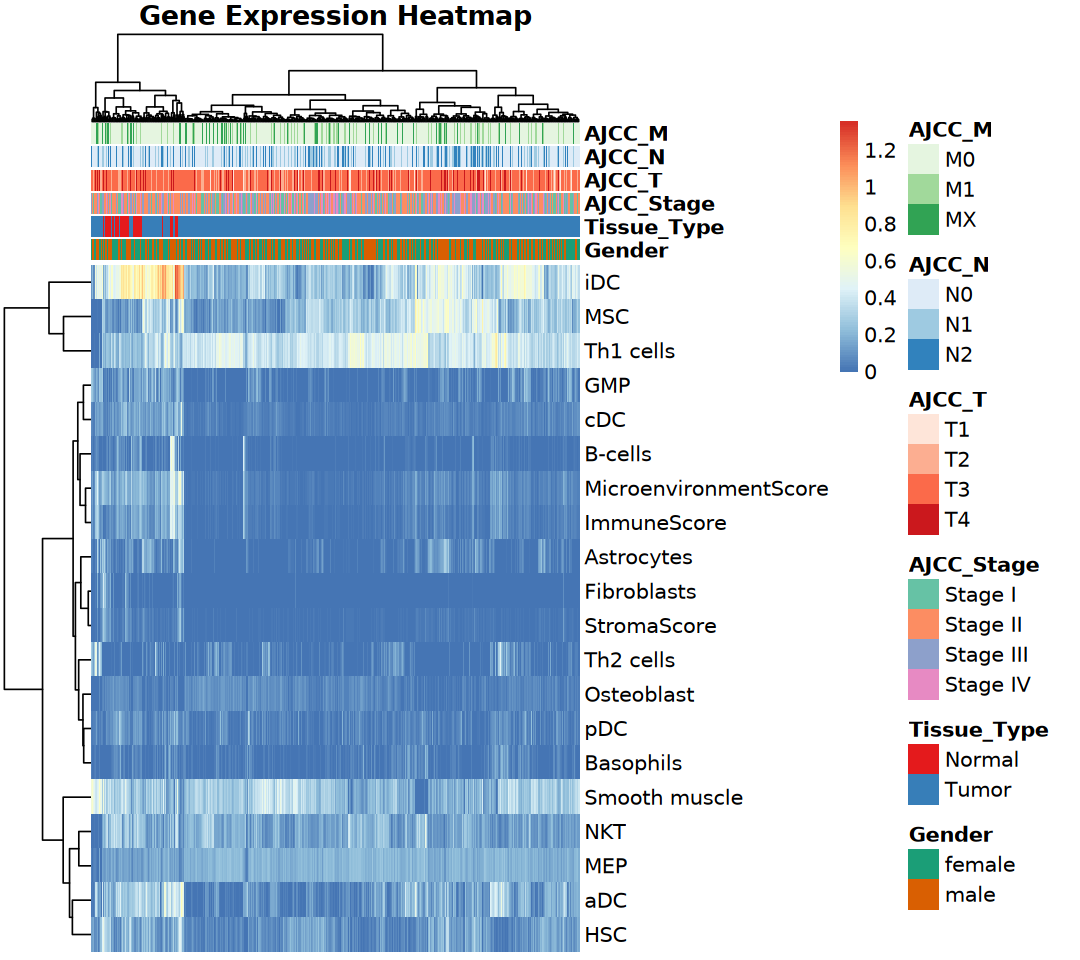

In [28]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    xcell_result[top_idx, ], 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    clustering_distance_rows = "euclidean",
    clustering_method = "ward.D2",
    main = "Gene Expression Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = TRUE)

In [29]:
plot_df <- xcell_result[top_idx, ] |> as.data.frame() |>
    rownames_to_column("Cell") |>
    pivot_longer(cols = -Cell, names_to = "Sample", values_to = "Score")

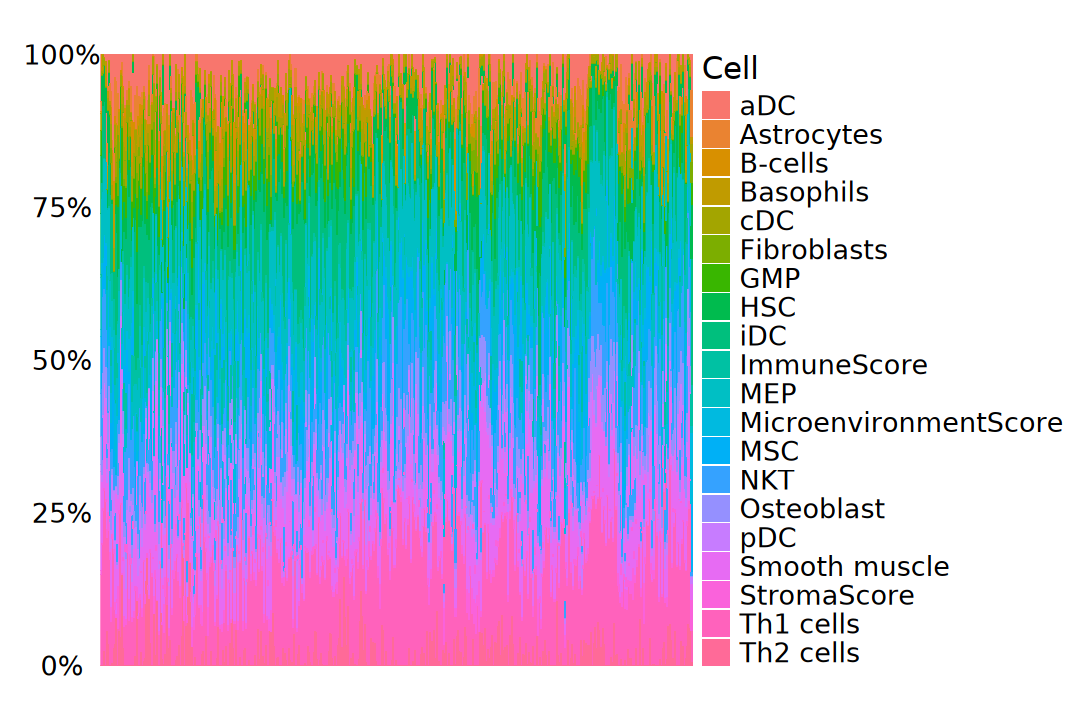

In [30]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(Sample, Score, fill = Cell)) +
    geom_bar(stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::label_percent()) + 
    labs(x = NULL, y = NULL) +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16))

### [MCPcounter](https://github.com/ebecht/MCPcounter)

> The Microenvironment Cell Populations-counter (MCP-counter) method enables robust quantification of the absolute abundance of eight immune and two stromal cell populations in heterogeneous tissues from transcriptomic data.
> - Becht, E., Giraldo, N.A., Lacroix, L. et al. Estimating the population abundance of tissue-infiltrating immune and stromal cell populations using gene expression. Genome Biol 17, 218 (2016). https://doi.org/10.1186/s13059-016-1070-5.

> [mMCP-counter](https://github.com/cit-bioinfo/mMCP-counter): Murine version of MCP-counter
> - Petitprez, F., Levy, S., Sun, CM. et al. The murine Microenvironment Cell Population counter method to estimate abundance of tissue-infiltrating immune and stromal cell populations in murine samples using gene expression. Genome Med 12, 86 (2020). https://doi.org/10.1186/s13073-020-00783-w.

In [31]:
# remotes::install_github("ebecht/MCPcounter",ref="master", subdir="Source")
suppressPackageStartupMessages(library(MCPcounter))

In [32]:
mcpcounter_genes <- read.table(
    "~/software/R/MCPcounter/Signatures/genes.txt", 
    sep = "\t", stringsAsFactors = FALSE, header = TRUE, 
    colClasses = "character", check.names = FALSE)

In [33]:
mcpcounter_result <- MCPcounter.estimate(
    norm_mat, featuresType = "HUGO_symbols", 
    genes = mcpcounter_genes)

# immunedeconv::deconvolute_mouse(norm_mat, "mmcp_counter")

In [34]:
dim(mcpcounter_result)
mcpcounter_result[1:6, 1:6]

[1]  10 514

,TCGA-5M-AAT6-01A,TCGA-AA-3552-01A,TCGA-AA-3867-01A,TCGA-AD-6895-01A,TCGA-AA-3560-01A,TCGA-CM-6676-01A
T cells,7.923899,7.7257910,2.535262,7.799507,5.5673562,2.97875093
CD8 T cells,3.028734,2.4518574,2.336330,2.919545,0.4224562,0.43565164
Cytotoxic lymphocytes,9.614105,4.5576668,0.940962,15.571238,1.8699539,0.88909376
B lineage,3274.283243,4290.6576653,1393.931846,51.380012,2268.3678010,99.58120301
NK cells,1.377590,0.5412974,0.531612,1.686334,0.2751280,0.08550628
Monocytic lineage,19.340621,12.3480664,10.393525,8.438259,9.1114879,5.25214870


In [35]:
plot_df <- mcpcounter_result |> as.data.frame() |>
    rownames_to_column("Cell") |>
    pivot_longer(cols = -Cell, names_to = "Sample", values_to = "Score")

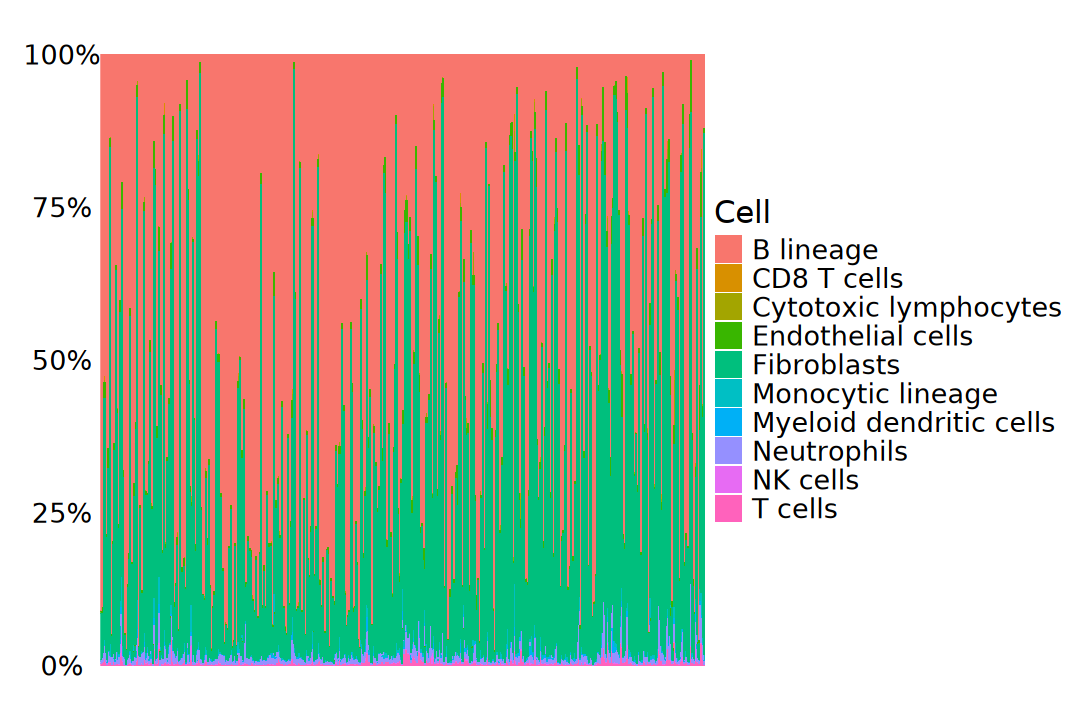

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(Sample, Score, fill = Cell)) +
    geom_bar(stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::label_percent()) + 
    labs(x = NULL, y = NULL) +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16))

### [ConsensusTME](https://github.com/cansysbio/ConsensusTME)

> ssGSEA framework to provide normalised enrichment scores for each of the cell types representing the relative abundance of cell types across multiple samples.
> - Alejandro Jiménez-Sánchez, Oliver Cast, Martin L. Miller; Comprehensive Benchmarking and Integration of Tumor Microenvironment Cell Estimation Methods. Cancer Res 15 December 2019; 79 (24): 6238–6246. https://doi.org/10.1158/0008-5472.CAN-18-3560.

In [37]:
# remotes::install_github("cansysbio/ConsensusTME")
suppressPackageStartupMessages(library(ConsensusTME))

In [38]:
consensus_result <- ConsensusTME::consensusTMEAnalysis(
    norm_mat, cancer = "COAD", statMethod = "ssgsea")

Producing ConsensusTME Estimates Using The Following Parameters:
 Statistical Framework: "ssgsea"
 Gene Sets For Cancer Type: "COAD"
 Sample Size: 514


ℹ GSVA version 2.4.9

ℹ Searching for rows with constant values

ℹ Calculating ssGSEA scores for 19 gene sets

ℹ Calculating ranks

ℹ Calculating rank weights

ℹ Normalizing ssGSEA scores

✔ Calculations finished



In [39]:
dim(consensus_result)
consensus_result[1:6, 1:6]

[1]  19 514

,TCGA-5M-AAT6-01A,TCGA-AA-3552-01A,TCGA-AA-3867-01A,TCGA-AD-6895-01A,TCGA-AA-3560-01A,TCGA-CM-6676-01A
B_cells,-0.01659754,0.01815547,-0.06337547,-0.08104904,-0.09597608,-0.17388151
Cytotoxic_cells,0.08377513,-0.07962839,-0.20510676,0.06257046,-0.14007130,-0.25955538
Dendritic_cells,0.21551080,0.12796237,0.04053108,0.11963844,0.05444880,-0.06680052
Eosinophils,0.15727579,0.10344502,0.03551875,0.08418021,0.05871072,-0.05925848
Macrophages,0.26185303,0.12856596,0.10745648,0.14213984,0.09670547,-0.02224890
Mast_cells,0.11597265,-0.01671208,-0.08233854,-0.03533367,-0.05371840,-0.09106721


## Deconvolution

> consider a given gene expression profile as a linear combination of pre-defined immune gene signatures present at different ratios. A linear regression model is often applied to estimate the coefficients of genes, which are later used to infer immune cell abundances or fractions.

### [TIMER2](http://timer.cistrome.org)

> [Timer](http://cistrome.org/TIMER/) is a web resource for systematical evaluations of the clinical impact of different immune cells in diverse cancer types.
> 
> [TIMER 2](https://compbio.cn/timer2/) is a comprehensive resource for systematical analysis of immune infiltrates across diverse cancer types.
> 
> linear least square regression
> 
> - Taiwen Li, Jingyu Fan, Binbin Wang, Nicole Traugh, Qianming Chen, Jun S. Liu, Bo Li, X. Shirley Liu; TIMER: A Web Server for Comprehensive Analysis of Tumor-Infiltrating Immune Cells. Cancer Res 1 November 2017; 77 (21): e108–e110. https://doi.org/10.1158/0008-5472.CAN-17-0307.
> - Hao Cui, Guile Zhao, Yiwen Lu, Siying Zuo, Dingyu Duan, Xiaobo Luo, Hang Zhao, Jing Li, Zexian Zeng, Qianming Chen, Taiwen Li, TIMER3: an enhanced resource for tumor immune analysis, Nucleic Acids Research, Volume 53, Issue W1, 7 July 2025, Pages W534–W541, https://doi.org/10.1093/nar/gkaf388.

### [CIBERSORT](https://github.com/Moonerss/CIBERSORT)

> v-Support Vector Regression
> - Newman, A., Liu, C., Green, M. et al. Robust enumeration of cell subsets from tissue expression profiles. Nat Methods 12, 453–457 (2015). https://doi.org/10.1038/nmeth.3337.

In [40]:
# remotes::install_github("bmbolstad/preprocessCore")
# remotes::install_github("Moonerss/CIBERSORT")
suppressPackageStartupMessages(library(CIBERSORT))

In [41]:
sig_matrix <- system.file("extdata", "LM22.txt", package = "CIBERSORT")

In [42]:
cibersort_result <- CIBERSORT::cibersort(sig_matrix, norm_mat, QN = FALSE)

In [43]:
dim(cibersort_result)
cibersort_result[1:6, 1:6]

[1] 514  25

,B cells naive,B cells memory,Plasma cells,T cells CD8,T cells CD4 naive,T cells CD4 memory resting
TCGA-5M-AAT6-01A,0.036744875,0.000000000,0.068267418,0.15792046,0,0.06605469
TCGA-AA-3552-01A,0.177879189,0.000000000,0.184365624,0.09313061,0,0.14547891
TCGA-AA-3867-01A,0.011040714,0.001208444,0.102255724,0.03726030,0,0.13822946
TCGA-AD-6895-01A,0.000000000,0.000000000,0.006407707,0.23219709,0,0.00000000
TCGA-AA-3560-01A,0.004914808,0.000000000,0.082379901,0.04097447,0,0.35409977
TCGA-CM-6676-01A,0.048072192,0.000000000,0.014593270,0.02461867,0,0.11848565


### [quanTIseq](https://github.com/icbi-lab/quanTIseq)

> constrained least square regression
> - Finotello, F., Mayer, C., Plattner, C. et al. Molecular and pharmacological modulators of the tumor immune contexture revealed by deconvolution of RNA-seq data. Genome Med 11, 34 (2019). https://doi.org/10.1186/s13073-019-0638-6.

In [44]:
# BiocManager::install("quantiseqr")
suppressPackageStartupMessages(library(quantiseqr))

In [45]:
quantiseq_result <- run_quantiseq(
    expression_data = norm_mat, signature_matrix = "TIL10",
    is_arraydata = FALSE, is_tumordata = TRUE, scale_mRNA = TRUE)

# immunedeconv::deconvolute(norm_mat, "quantiseq")


Running quanTIseq deconvolution module


Gene expression normalization and re-annotation (arrays: FALSE)


Removing 17 noisy genes


Removing 15 genes with high expression in tumors


Signature genes found in data set: 132/138 (95.65%)


Mixture deconvolution (method: lsei)


Deconvolution successful!



In [46]:
dim(quantiseq_result)
quantiseq_result[1:6, 1:6]

[1] 514  12

,Sample,B.cells,Macrophages.M1,Macrophages.M2,Monocytes,Neutrophils
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TCGA-5M-AAT6-01A,TCGA-5M-AAT6-01A,0.010436585,0.06571422,0.05527169,0,0.01827330
TCGA-AA-3552-01A,TCGA-AA-3552-01A,0.010216562,0.03004152,0.06898280,0,0.04101047
TCGA-AA-3867-01A,TCGA-AA-3867-01A,0.003541270,0.01282659,0.04840792,0,0.10033354
TCGA-AD-6895-01A,TCGA-AD-6895-01A,0.003362022,0.09652925,0.02828758,0,0.04924431
TCGA-AA-3560-01A,TCGA-AA-3560-01A,0.001463018,0.02393215,0.04700629,0,0.05237177
TCGA-CM-6676-01A,TCGA-CM-6676-01A,0.002749450,0.03180467,0.02470536,0,0.06738435


### [EPIC](https://github.com/GfellerLab/EPIC)

> constrained least square regression
> - Julien RacleKaat de JongePetra BaumgaertnerDaniel E SpeiserDavid Gfeller (2017) Simultaneous enumeration of cancer and immune cell types from bulk tumor gene expression data eLife 6:e26476.

In [47]:
# remotes::install_github("GfellerLab/EPIC", build_vignettes = TRUE)
suppressPackageStartupMessages(library(EPIC))

In [48]:
epic_result <- EPIC(bulk = norm_mat)

Warning message in EPIC(bulk = norm_mat):
“The optimization didn't fully converge for some samples:
TCGA-AA-3972-01A; TCGA-CM-6680-01A; TCGA-A6-2676-01A; TCGA-A6-2680-11A; TCGA-CA-6716-01A; TCGA-A6-2677-01B; TCGA-AA-3655-01A; TCGA-AA-3875-01A; TCGA-A6-A565-01A; TCGA-AD-6899-01A; TCGA-AZ-4323-01A; TCGA-AZ-6600-01A; TCGA-AY-5543-01A; TCGA-AA-A00Q-01A; TCGA-WS-AB45-01A; TCGA-D5-6534-01A; TCGA-AA-A01V-01A; TCGA-DM-A28C-01A
 - check fit.gof for the convergeCode and convergeMessage”


In [49]:
dim(epic_result$mRNAProportions)
epic_result$mRNAProportions[1:6, 1:6]

[1] 514   8

,Bcells,CAFs,CD4_Tcells,CD8_Tcells,Endothelial,Macrophages
TCGA-5M-AAT6-01A,0.0082559791,0.33590371,0.02883936,3.249042e-07,0.05929137,0.08740146
TCGA-AA-3552-01A,0.0157924101,0.05155882,0.04540124,8.838111e-03,0.04692176,0.06836449
TCGA-AA-3867-01A,0.0080642785,0.19516250,0.01879391,5.760020e-03,0.03747132,0.04936081
TCGA-AD-6895-01A,0.0011451449,0.15450508,0.04628896,1.371381e-03,0.03679673,0.03550143
TCGA-AA-3560-01A,0.0035911985,0.02067304,0.03709434,4.529056e-03,0.01664420,0.01482760
TCGA-CM-6676-01A,0.0009179413,0.09054188,0.02876574,4.348916e-03,0.03279392,0.01721643


## [ImmuneDeconv](https://github.com/omnideconv/immunedeconv)

> R package for unified access to computational methods for estimating immune cell fractions from bulk RNA sequencing data.
> - Gregor Sturm, Francesca Finotello, Florent Petitprez, Jitao David Zhang, Jan Baumbach, Wolf H Fridman, Markus List, Tatsiana Aneichyk, Comprehensive evaluation of transcriptome-based cell-type quantification methods for immuno-oncology, Bioinformatics, Volume 35, Issue 14, July 2019, Pages i436–i445, https://doi.org/10.1093/bioinformatics/btz363
> - Lorenzo Merotto, Gregor Sturm, Alexander Dietrich, Markus List, Francesca Finotello, Making mouse transcriptomics deconvolution accessible with immunedeconv, Bioinformatics Advances, Volume 4, Issue 1, 2024, vbae032, https://doi.org/10.1093/bioadv/vbae032

In [50]:
# remotes::install_github("omnideconv/immunedeconv")
suppressPackageStartupMessages(library(immunedeconv))

In [51]:
# conversion to orthologous gene names
# norm_mat <- immunedeconv::mouse_genes_to_human(norm_mat)

In [52]:
# source("CIBERSORT.R")
# result <- immunedeconv::deconvolute(norm_mat, "cibersort")
# result <- CIBERSORT(
#     sig_matrix, norm_mat, abs_method = "sig.score", 
#     perm = 100, QN = FALSE, absolute = TRUE)

# ?. Immune Repertoire

## [TRUST4](https://github.com/liulab-dfci/TRUST4)

> TRUST4 is a computational tool to analyze TCR and BCR sequences using unselected RNA sequencing data, profiled from fluid and solid tissues, including tumors. TRUST4 performs de novo assembly on V, J, C genes including the hypervariable complementarity-determining region 3 (CDR3) and reports consensus contigs of BCR/TCR sequences. TRUST4 then realigns the contigs to IMGT reference gene sequences to identify the corresponding gene and CDR3 details. TRUST4 supports both single-end and paired-end bulk or single-cell sequencing data with any read length.
> - Song, L., Cohen, D., Ouyang, Z. et al. TRUST4: immune repertoire reconstruction from bulk and single-cell RNA-seq data. Nat Methods 18, 627–630 (2021). https://doi.org/10.1038/s41592-021-01142-2.

# ?. Immune Response

## [TIDE](https://github.com/jingxinfu/TIDEpy)

> TIDE (Tumor Immune Dysfunction and Exclusion) is a computational framework developed to evaluate the potential of tumor immune escape from the gene expression profiles of cancer samples.
> - Jiang, P., Gu, S., Pan, D. et al. Signatures of T cell dysfunction and exclusion predict cancer immunotherapy response. Nat Med 24, 1550–1558 (2018). https://doi.org/10.1038/s41591-018-0136-1.
> - Fu, J., Li, K., Zhang, W. et al. Large-scale public data reuse to model immunotherapy response and resistance. Genome Med 12, 21 (2020). https://doi.org/10.1186/s13073-020-0721-z.

## [MSIsensor2](https://github.com/niu-lab/msisensor2)

> MSIsensor2 is a novel algorithm based machine learning, featuring a large upgrade in the microsatellite instability (MSI) detection for tumor only sequencing data, including Cell-Free DNA (cfDNA), Formalin-Fixed Paraffin-Embedded(FFPE) and other sample types.

## [CIDE](https://cide.ccr.cancer.gov/)

> - Gong L, Luo J, Yang E. et al. Cancer immunology data engine reveals secreted AOAH as a potential immunotherapy. Cell, 2025; 188, 5062-5080.e32

# Reference

> 1. [Tutorial of RNA-seq tumor immunity analysis](https://liulab-dfci.github.io/RIMA/)